# Baseline 3: 63-Day NFLX Closing Price Forecast

**Objective:** Forecast NFLX closing prices for the next 63 business weekdays, including lower and upper 95% prediction bounds, and save the result to `./data/forecast_basic.csv`.

This builds on Baseline 1, which found that closing prices are non-stationary while daily log returns are stationary. For this basic multi-step forecast, we fit an **ARIMA(1,1,0)** model to log closing prices. First differencing the log-price series models changes in log price.

**Date note:** The generated future dates exclude weekends (Monday–Friday), but do not automatically exclude US market holidays.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX

from tslab import config
from tslab.data import load_market_data

warnings.filterwarnings("ignore")
%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 5)

FORECAST_HORIZON = 63
CONFIDENCE_LEVEL = 0.95

print("Target ticker:", config.TARGET_TICKER)
assert config.TARGET_TICKER == "NFLX", (
    "Please set TARGET_TICKER = 'NFLX' in tslab/config.py"
)

Target ticker: NFLX


## 1. Load and prepare the NFLX closing-price series

In [2]:
frame = load_market_data()

if "Close" not in frame.columns:
    raise KeyError("The market data must contain a 'Close' column.")

close = frame["Close"].dropna().astype(float).sort_index()

if close.empty:
    raise ValueError("No closing-price observations were loaded.")
if (close <= 0).any():
    raise ValueError("Closing prices must be positive before taking logarithms.")

log_close = np.log(close)

print(f"Observations available : {len(close)}")
print(f"First observation      : {close.index.min().date()}")
print(f"Last observation       : {close.index.max().date()}")
print(f"Latest closing price   : ${close.iloc[-1]:.2f}")

display(close.tail().to_frame("NFLX Close"))

Loaded 2981 trading days of NFLX, 2015-01-02 to 2026-11-09, with 7 predictor series.
Observations available : 2981
First observation      : 2015-01-02
Last observation       : 2026-11-09
Latest closing price   : $63.95


,NFLX Close
Date,
2026-11-03,63.419998
2026-11-04,66.389999
2026-11-05,65.559998
2026-11-06,63.410000
2026-11-09,63.950001


## 2. Fit the forecasting model

We fit an ARIMA(1,1,0) model to log closing prices:
- `d=1` differences the log-price series once.
- `p=1` allows the differenced series to depend on its previous value.
- `q=0` means no moving-average error term is included.

The model is fitted using the available historical data only.

In [5]:
# Transform closing prices into log prices
log_close = np.log(close)

# Use a supported integer index for Statsmodels forecasting.
# We will assign the actual future dates separately in Section 3.
log_close_model = pd.Series(
    log_close.to_numpy(),
    index=pd.RangeIndex(start=0, stop=len(log_close)),
    name="log_close"
)

# Fit the ARIMA(1,1,0) model
model = SARIMAX(
    log_close_model,
    order=(1, 1, 0),
    trend="t",
    enforce_stationarity=False,
    enforce_invertibility=False
)

model_fit = model.fit(disp=False)

print(model_fit.summary())


                               SARIMAX Results                                
Dep. Variable:              log_close   No. Observations:                 2981
Model:               SARIMAX(1, 1, 0)   Log Likelihood                6530.822
Date:                Sun, 22 Nov 2026   AIC                         -13055.643
Time:                        01:57:56   BIC                         -13037.645
Sample:                             0   HQIC                        -13049.167
                               - 2981                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
drift       2.186e-07   3.16e-07      0.693      0.488      -4e-07    8.37e-07
ar.L1         -0.0010      0.016     -0.064      0.949      -0.033       0.031
sigma2         0.0007    5.2e-06    140.364      0.0

## 3. Produce the 63-business-day forecast and prediction bounds

In [6]:

## 3. Produce the 63-business-day forecast and prediction bounds

forecast_result = model_fit.get_forecast(steps=FORECAST_HORIZON)

# Extract forecast and confidence intervals on the log-price scale
log_forecast = forecast_result.predicted_mean
log_conf_int = forecast_result.conf_int(alpha=1 - CONFIDENCE_LEVEL)

# Generate 63 future weekdays after the last observed trading date
future_dates = pd.bdate_range(
    start=close.index[-1] + pd.offsets.BDay(1),
    periods=FORECAST_HORIZON
)

# Convert log-price forecasts and bounds back to dollar prices
forecast_values = np.exp(np.asarray(log_forecast))
lower_values = np.exp(log_conf_int.iloc[:, 0].to_numpy())
upper_values = np.exp(log_conf_int.iloc[:, 1].to_numpy())

# Create the forecast DataFrame
forecast_df = pd.DataFrame({
    "date": future_dates,
    "forecast": forecast_values,
    "lower": lower_values,
    "upper": upper_values
})

forecast_df = forecast_df[["date", "forecast", "lower", "upper"]]

# Validate forecast output
assert len(forecast_df) == FORECAST_HORIZON
assert forecast_df[["forecast", "lower", "upper"]].notna().all().all()
assert (forecast_df["lower"] <= forecast_df["forecast"]).all()
assert (forecast_df["forecast"] <= forecast_df["upper"]).all()

display(forecast_df.head(10).round(2))

print("\nForecast horizon:", len(forecast_df), "business days")
print("First forecast date:", forecast_df["date"].iloc[0].date())
print("Last forecast date:", forecast_df["date"].iloc[-1].date())


,date,forecast,lower,upper
0,2026-11-10,63.99,60.69,67.47
1,2026-11-11,64.03,59.41,69.01
2,2026-11-12,64.07,58.46,70.23
3,2026-11-13,64.12,57.68,71.27
4,2026-11-16,64.16,57.00,72.22
5,2026-11-17,64.20,56.40,73.08
6,2026-11-18,64.24,55.85,73.89
7,2026-11-19,64.28,55.35,74.66
8,2026-11-20,64.33,54.88,75.39
9,2026-11-23,64.37,54.45,76.09



Forecast horizon: 63 business days
First forecast date: 2026-11-10
Last forecast date: 2027-02-04


## 4. Save the forecast to `./data/forecast_basic.csv`

In [7]:
output_dir = Path("./data")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "forecast_basic.csv"

forecast_to_save = forecast_df.copy()
forecast_to_save["date"] = forecast_to_save["date"].dt.strftime("%Y-%m-%d")
forecast_to_save.to_csv(output_path, index=False)

saved_forecast = pd.read_csv(output_path)
print("Forecast saved to:", output_path.resolve())
print("CSV columns:", list(saved_forecast.columns))
print("Saved rows:", len(saved_forecast))
display(saved_forecast.head())

Forecast saved to: D:\STRATH\BBIT\4thYear\4.1\BI\Labs\TimeSeriesForecasting-202604-d3\data\forecast_basic.csv
CSV columns: ['date', 'forecast', 'lower', 'upper']
Saved rows: 63


,date,forecast,lower,upper
0,2026-11-10,63.991131,60.690596,67.471160
1,2026-11-11,64.032816,59.414797,69.009772
2,2026-11-12,64.074542,58.462624,70.225157
3,2026-11-13,64.116308,57.677579,71.273814
4,2026-11-16,64.158116,56.999064,72.216341


## 5. Visualise the historical prices and 63-day forecast

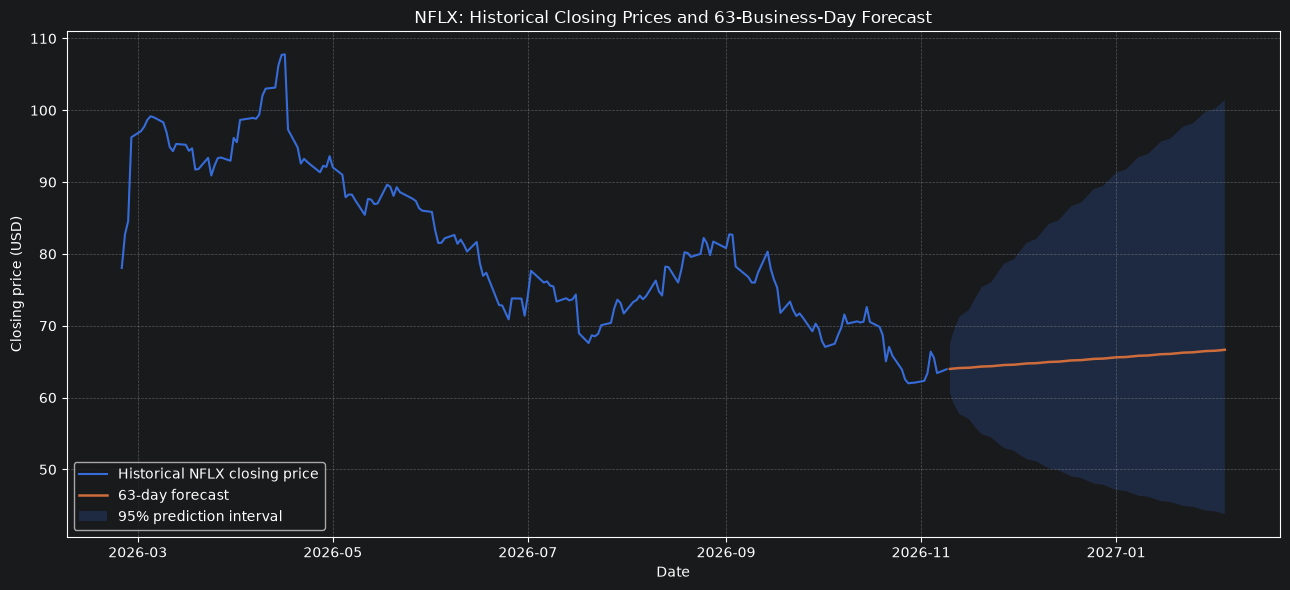

In [8]:
history_to_plot = close.tail(180)

plt.figure(figsize=(13, 6))
plt.plot(history_to_plot.index, history_to_plot.values,
         label="Historical NFLX closing price", linewidth=1.5)
plt.plot(forecast_df["date"], forecast_df["forecast"],
         label="63-day forecast", linewidth=1.8)
plt.fill_between(
    forecast_df["date"],
    forecast_df["lower"],
    forecast_df["upper"],
    alpha=0.2,
    label="95% prediction interval"
)
plt.title("NFLX: Historical Closing Prices and 63-Business-Day Forecast")
plt.xlabel("Date")
plt.ylabel("Closing price (USD)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## 6. Baseline 3 conclusion

The notebook generates a 63-business-day NFLX closing-price forecast using an ARIMA(1,1,0) model fitted to log closing prices. It includes lower and upper 95% prediction bounds to show the uncertainty around the projected prices.

The output is saved as `./data/forecast_basic.csv` with the required columns: `date`, `forecast`, `lower`, and `upper`.

**Interpretation:** This is a statistical projection based on historical prices, not a guarantee of future market performance. The prediction interval generally becomes wider further into the forecast horizon as uncertainty accumulates.